# House Prices and Monetary Policy: Data and VAR Analysis

This notebook runs the full analysis for the thesis. It downloads or loads the data, draws the exploratory figures, and estimates the response of house prices to a federal funds rate shock.

The code lives in the `src/` package, so this notebook only calls functions and shows the results.

In [1]:
%load_ext autoreload
%autoreload 2

from src import config, plots
from src.data_processing import compute_permits_per_capita, load_data, prepare_var_data
from src.fred_download import data_files_exist, download_and_save
from src.var_irf import run_var_analysis

## 1. Data

The data comes from FRED and is stored in `data_csv/`. It has two parts:

- **VAR data** (1987/01 to 2007/07): Case-Shiller house price indices, the federal funds rate, unemployment and PCE inflation.
- **Exploratory data** (from 2000/01, or 1959/01 for housing starts and recessions): building permits, population, housing starts and the recession indicator.

The download runs only if the CSV files are missing. Set `REFRESH_DATA = True` to download everything again and overwrite them, which requires `FRED_API_KEY` in the `.env` file.

In [2]:
REFRESH_DATA = False

if REFRESH_DATA or not data_files_exist():
    download_and_save()

In [3]:
df_visuals = load_data(config.VISUALS_DATA_PATH)
df_var = load_data(config.VAR_DATA_PATH)

print("Visuals Data Range:", df_visuals.index.min(), "to", df_visuals.index.max())
print("VAR Data Range:", df_var.index.min(), "to", df_var.index.max())
display(df_var.head())

Visuals Data Range: 1959-01-01 00:00:00 to 2025-08-01 00:00:00
VAR Data Range: 1987-01-01 00:00:00 to 2007-07-01 00:00:00


,cs,cs10,ffr,unemp,pce_rate,charlotte,cleveland,denver,las vegas,new york
1987-01-01,63.732,63.103814,6.43,6.6,3.16,63.559024,54.057393,50.348017,66.418966,74.678440
1987-02-01,64.131,63.804972,6.10,6.6,3.22,64.028844,54.229218,50.160468,67.574198,76.043687
1987-03-01,64.467,64.425674,6.13,6.6,3.41,64.105242,54.365756,50.383478,67.850132,77.237075
1987-04-01,64.972,65.063393,6.37,6.3,3.57,64.892990,54.155370,50.744628,68.186064,78.281527
1987-05-01,65.546,65.815103,6.85,6.3,3.66,65.222790,54.726192,50.763538,67.927091,79.675331


## 2. Exploratory Analysis

### 2.1 Permits per Capita
Building permits divided by population, at the national and metro levels. This normalizes permits by the size of the population.

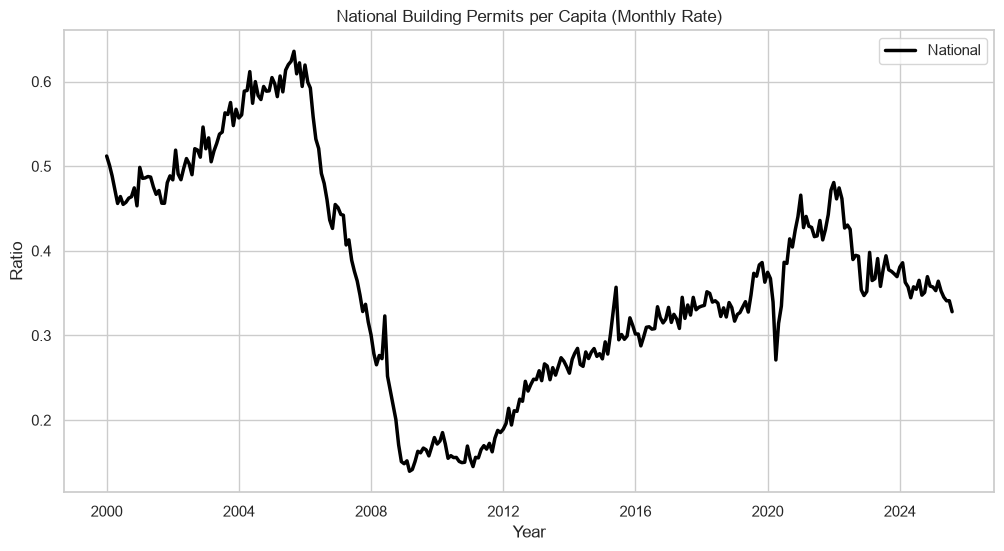

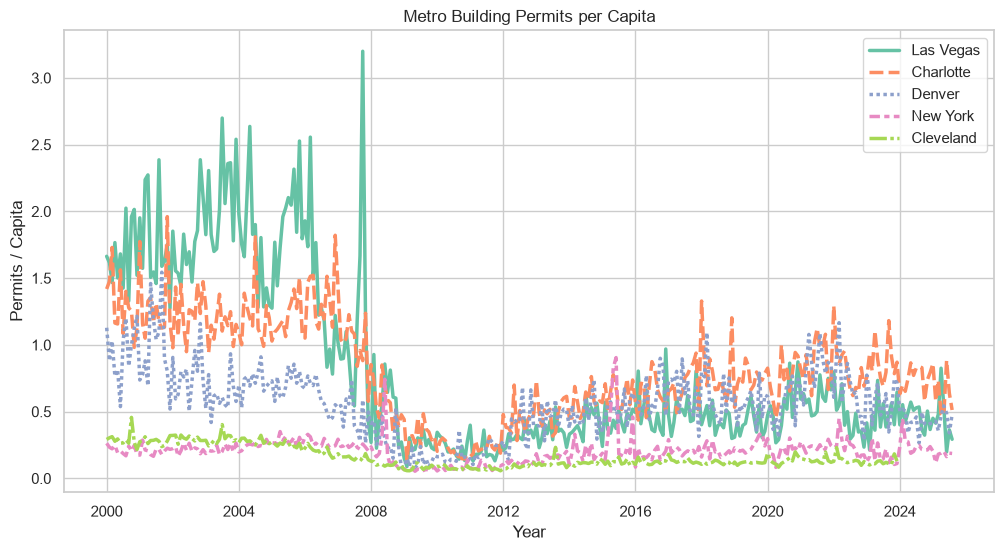

In [4]:
df_per_capita = compute_permits_per_capita(df_visuals)

plots.plot_national_permits_per_capita(df_per_capita)
plots.plot_metro_permits_per_capita(df_per_capita)

### 2.2 Case-Shiller House Price Indices
Case-Shiller indices for the nation, the 10-City Composite and the selected metro areas.

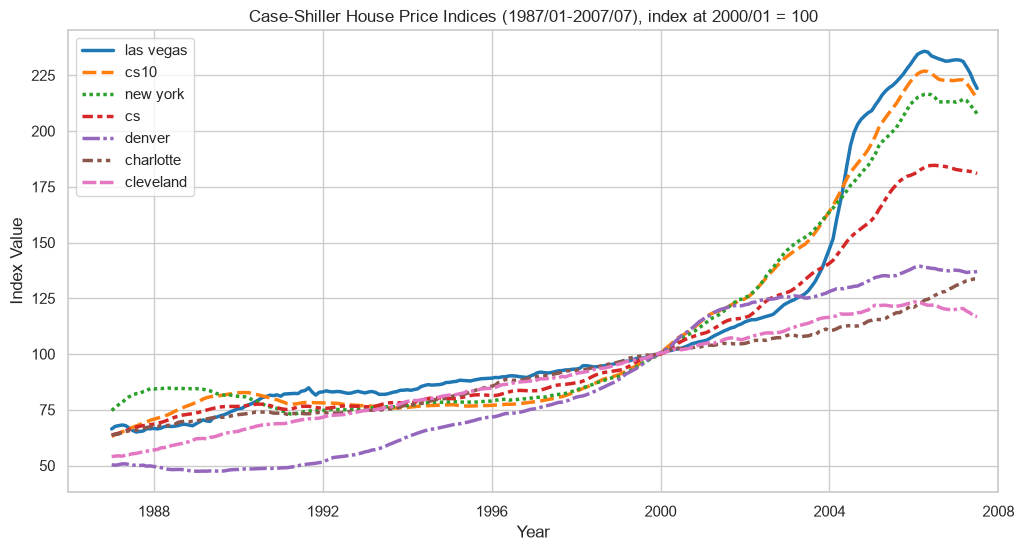

In [5]:
plots.plot_house_price_indices(df_var)

### 2.3 Economic Indicators
The federal funds rate, unemployment rate and PCE inflation from 1987.

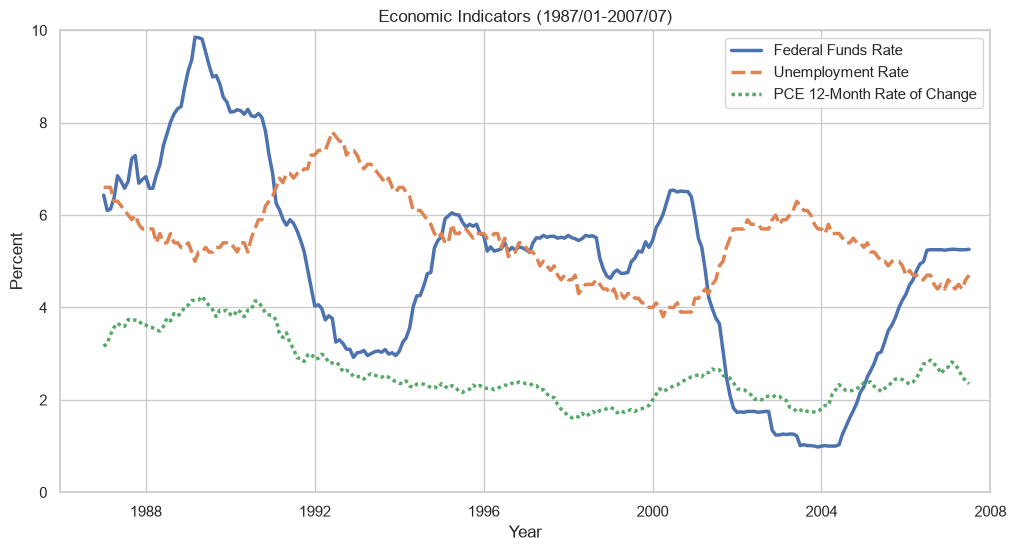

In [6]:
plots.plot_economic_indicators(df_var)

### 2.4 Housing Starts and Recessions
Housing starts from 1959 with recession periods shaded.

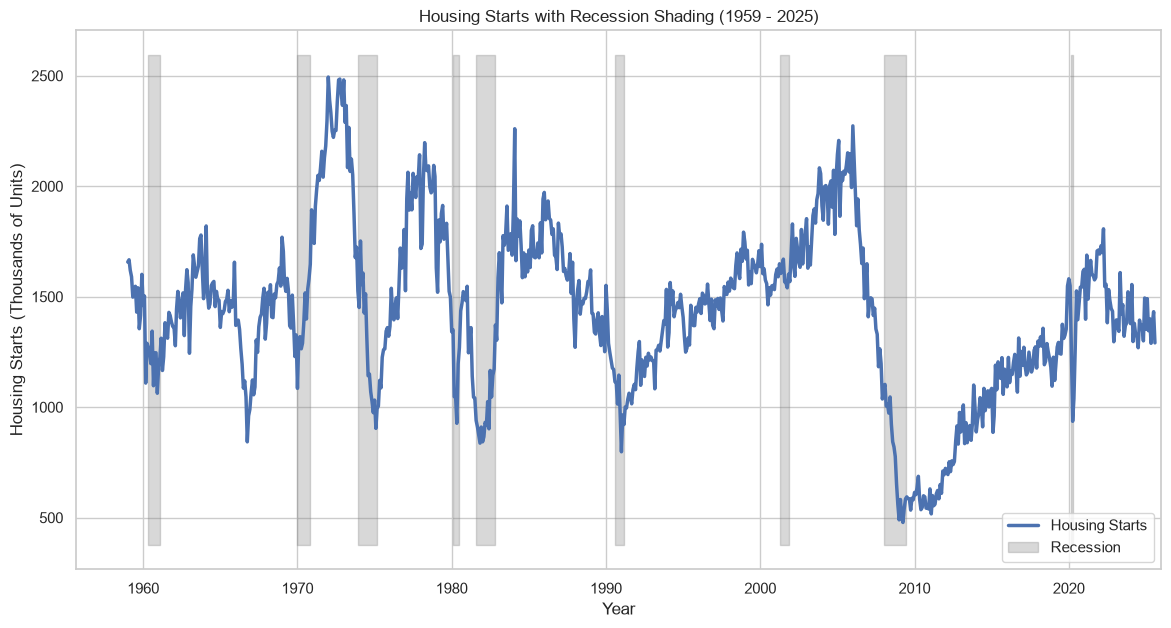

In [7]:
plots.plot_housing_starts(df_visuals)

## 3. VAR Analysis

### 3.1 Model Data
Each model uses the log of one Case-Shiller index together with unemployment, PCE inflation and the federal funds rate.

In [8]:
df_model = prepare_var_data(df_var)

df_model.head()

,cs,cs10,ffr,unemp,pce_rate,charlotte,cleveland,denver,lasvegas,newyork,log_cs,log_cs10,log_newyork,log_lasvegas,log_denver,log_charlotte,log_cleveland
Date,,,,,,,,,,,,,,,,,
1987-01-01,63.732,63.103814,6.43,6.6,3.16,63.559024,54.057393,50.348017,66.418966,74.678440,4.154687,4.144781,4.313191,4.195983,3.918959,4.151969,3.990046
1987-02-01,64.131,63.804972,6.10,6.6,3.22,64.028844,54.229218,50.160468,67.574198,76.043687,4.160928,4.155831,4.331308,4.213226,3.915227,4.159334,3.993220
1987-03-01,64.467,64.425674,6.13,6.6,3.41,64.105242,54.365756,50.383478,67.850132,77.237075,4.166153,4.165512,4.346880,4.217301,3.919663,4.160526,3.995734
1987-04-01,64.972,65.063393,6.37,6.3,3.57,64.892990,54.155370,50.744628,68.186064,78.281527,4.173956,4.175362,4.360312,4.222240,3.926806,4.172740,3.991857
1987-05-01,65.546,65.815103,6.85,6.3,3.66,65.222790,54.726192,50.763538,67.927091,79.675331,4.182752,4.186849,4.377960,4.218435,3.927178,4.177809,4.002342


### 3.2 Estimation
A separate VAR with 12 lags is estimated for each house price index, with the Cholesky ordering unemployment, PCE inflation, federal funds rate, log house prices.

The impulse responses and their confidence bands replicate Stata's `irf create, step(60) bs reps(500)`. The residual bootstrap runs 500 replications per model, so this cell takes a while.

In [9]:
irf_results = run_var_analysis(
    df_model,
    cs_cols=config.CS_COLS,
    start_date=config.VAR_START_DATE,
    end_date=config.VAR_END_DATE,
    lags=config.VAR_LAGS,
    irf_steps=config.IRF_STEPS,
    # here 100 bootstraps instead of 500 to run faster
    n_boot=100,
    seed=config.BOOTSTRAP_SEED,
)

Sample Window (including 12 lags): 1987-01-01 to 2007-07-01
Model        | Eff. Obs (T) | FFR Residual SD  | FFR Cholesky Shock
------------------------------------------------------------------
cs           | 235          | 0.1247703        | 0.12176053        
cs10         | 235          | 0.1268970        | 0.12438087        
newyork      | 235          | 0.1261822        | 0.12374911        
lasvegas     | 235          | 0.1254066        | 0.12249494        
denver       | 235          | 0.1240484        | 0.12159632        
charlotte    | 235          | 0.1243224        | 0.12239021        
cleveland    | 235          | 0.1250870        | 0.12294897        


### 3.3 Impulse Responses
Response of log house prices to a one standard deviation federal funds rate shock, with 95% bootstrapped confidence intervals.

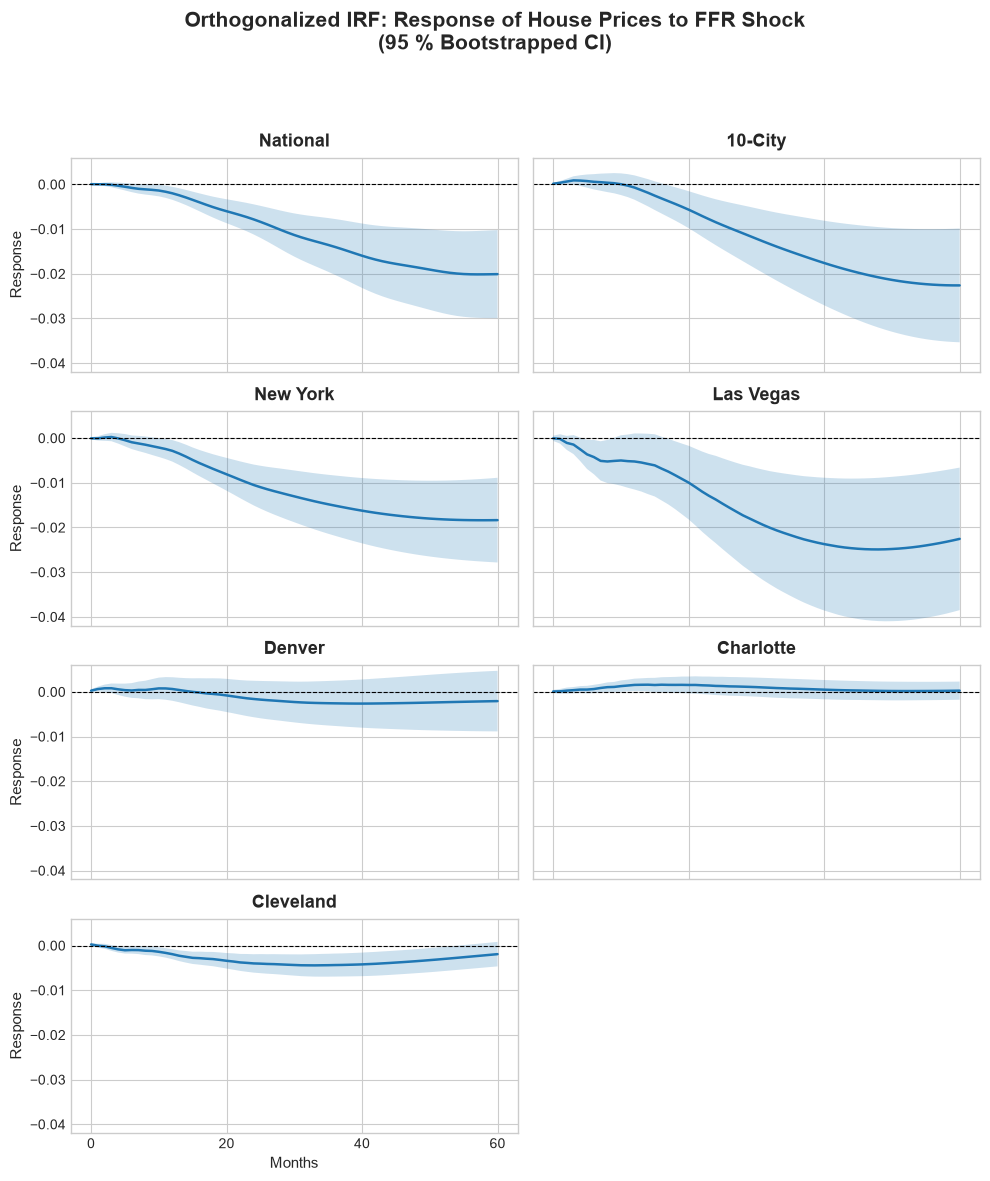

In [10]:
plots.plot_irf_grid(irf_results, config.CS_NAMES)